# 👥 Análise de Comparecimento e Abstenção

Foco em participação eleitoral, seções e comportamento do eleitorado.

**Visualizações:**
- Comparecimento vs Abstenção
- Seções apuradas vs pendentes
- Votos válidos, brancos, nulos, anulados
- Evolução de participação
- Taxa de abstenção ao longo do tempo

In [1]:

import json
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Setup plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['figure.dpi'] = 120

# Find repo root and data dir robustly
def find_data_dir():
    candidates = [
        Path("../data"),
        Path("data"),
        Path("./data"),
        Path(__file__).parent / "../data" if '__file__' in globals() else None,
    ]
    # Also try from cwd
    cwd = Path.cwd()
    for p in [cwd / "data", cwd.parent / "data", cwd / "../data", Path("/home/user/eleicoes-data/data")]:
        candidates.append(p)
    for c in candidates:
        if c and c.exists() and list(c.glob("*.json")):
            return c
    # fallback: search recursively up to 3 levels
    for base in [Path.cwd(), Path.cwd().parent, Path("/home/user/eleicoes-data")]:
        for sub in [base, base / "eleicoes-data"]:
            d = sub / "data"
            if d.exists():
                return d
    return Path("../data")

DATA_DIR = find_data_dir()
print(f"📁 Data directory: {DATA_DIR.resolve()}")

files = sorted(DATA_DIR.glob("*.json"))
print(f"📊 Found {len(files)} snapshot files")
if files:
    print(f"   First: {files[0].name}")
    print(f"   Last:  {files[-1].name}")


def load_snapshot(path):
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)

def extract_candidates(snapshot):
    """Flatten TSE payload into list of dicts."""
    rows = []
    payload = snapshot['data']
    for cargo in payload.get('carg', []):
        for agr in cargo.get('agr', []):
            for par in agr.get('par', []):
                for cand in par.get('cand', []):
                    rows.append({
                        'seq': cand.get('seq'),
                        'numero': cand.get('n'),
                        'nome_completo': cand.get('nm'),
                        'nome_urna': cand.get('nmu'),
                        'partido': par.get('sg'),
                        'partido_nome': par.get('nm'),
                        'agregacao': agr.get('nm'),
                        'votos': int(cand.get('vap', 0) or 0),
                        'percentual': float(str(cand.get('pvap', '0')).replace(',', '.') or 0),
                        'percentual_n': float(str(cand.get('pvapn', '0')).replace(',', '.') or 0),
                        'situacao': cand.get('st', ''),
                        'eleito': cand.get('e', ''),
                    })
    rows.sort(key=lambda x: x['votos'], reverse=True)
    return rows

def load_all_snapshots():
    all_data = []
    for fp in sorted(DATA_DIR.glob("*.json")):
        doc = load_snapshot(fp)
        meta = doc['metadata']
        data = doc['data']
        cands = extract_candidates(doc)
        # sections
        s = data.get('s', {})
        v = data.get('v', {})
        e = data.get('e', {})
        all_data.append({
            'file': fp.name,
            'path': fp,
            'scraped_at_utc': meta.get('scraped_at_utc'),
            'scraped_at_brasilia': meta.get('scraped_at_brasilia'),
            'tse_generated': meta.get('tse_file_generated_at'),
            'secoes_total': int(s.get('ts', 0) or 0),
            'secoes_apuradas': int(s.get('st', 0) or 0),
            'pct_apuradas': float(str(s.get('pst', '0')).replace(',', '.') or 0),
            'eleitorado': int(e.get('te', 0) or 0),
            'comparecimento': int(e.get('c', 0) or 0),
            'abstencao': int(e.get('a', 0) or 0),
            'votos_validos': int(v.get('vv', 0) or 0),
            'votos_brancos': int(v.get('vb', 0) or 0),
            'votos_nulos': int(v.get('vn', 0) or 0),
            'candidatos': cands,
            'metadata': meta,
            'raw': doc
        })
    return all_data

# Load once for convenience
all_snapshots = load_all_snapshots()
latest = all_snapshots[-1] if all_snapshots else None
if latest:
    print(f"✅ Latest snapshot: {latest['file']} | {latest['scraped_at_utc']}")
    print(f"   Seções: {latest['secoes_apuradas']}/{latest['secoes_total']} ({latest['pct_apuradas']}%)")


📁 Data directory: /home/user/eleicoes-data/data
📊 Found 43 snapshot files
   First: presidente_br_20261005_000211Z.json
   Last:  presidente_br_20261014_192215Z.json
✅ Latest snapshot: presidente_br_20261014_192215Z.json | 2026-10-14T19:22:15Z
   Seções: 499248/499248 (100.0%)


## 1. Dados de Participação - Último Snapshot

In [2]:

print(f"Eleitorado total: {latest['eleitorado']:,}")
print(f"Comparecimento: {latest['comparecimento']:,} ({latest['comparecimento']/latest['eleitorado']*100:.2f}%)")
print(f"Abstenção: {latest['abstencao']:,} ({latest['abstencao']/latest['eleitorado']*100:.2f}%)")
print()
print(f"Seções totais: {latest['secoes_total']:,}")
print(f"Seções apuradas: {latest['secoes_apuradas']:,}")
print(f"Seções não apuradas: {latest['secoes_total'] - latest['secoes_apuradas']:,}")
print()
print(f"Votos válidos: {latest['votos_validos']:,}")
print(f"Brancos: {latest['votos_brancos']:,}")
print(f"Nulos: {latest['votos_nulos']:,}")

df_turnout = pd.DataFrame([{
    'categoria': 'Comparecimento',
    'quantidade': latest['comparecimento'],
    'pct_eleitorado': latest['comparecimento']/latest['eleitorado']*100
}, {
    'categoria': 'Abstenção',
    'quantidade': latest['abstencao'],
    'pct_eleitorado': latest['abstencao']/latest['eleitorado']*100
}])
df_turnout


Eleitorado total: 158,745,502
Comparecimento: 125,275,835 (78.92%)
Abstenção: 33,469,244 (21.08%)

Seções totais: 499,248
Seções apuradas: 499,248
Seções não apuradas: 0

Votos válidos: 119,300,788
Brancos: 2,300,798
Nulos: 3,669,003


,categoria,quantidade,pct_eleitorado
0,Comparecimento,125275835,78.916148
1,Abstenção,33469244,21.083586


## 2. Gráficos de Participação

/tmp/ipykernel_2087/2456562800.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_turnout, x='categoria', y='quantidade', palette=['#3498db','#e74c3c'], ax=axes[0,1])


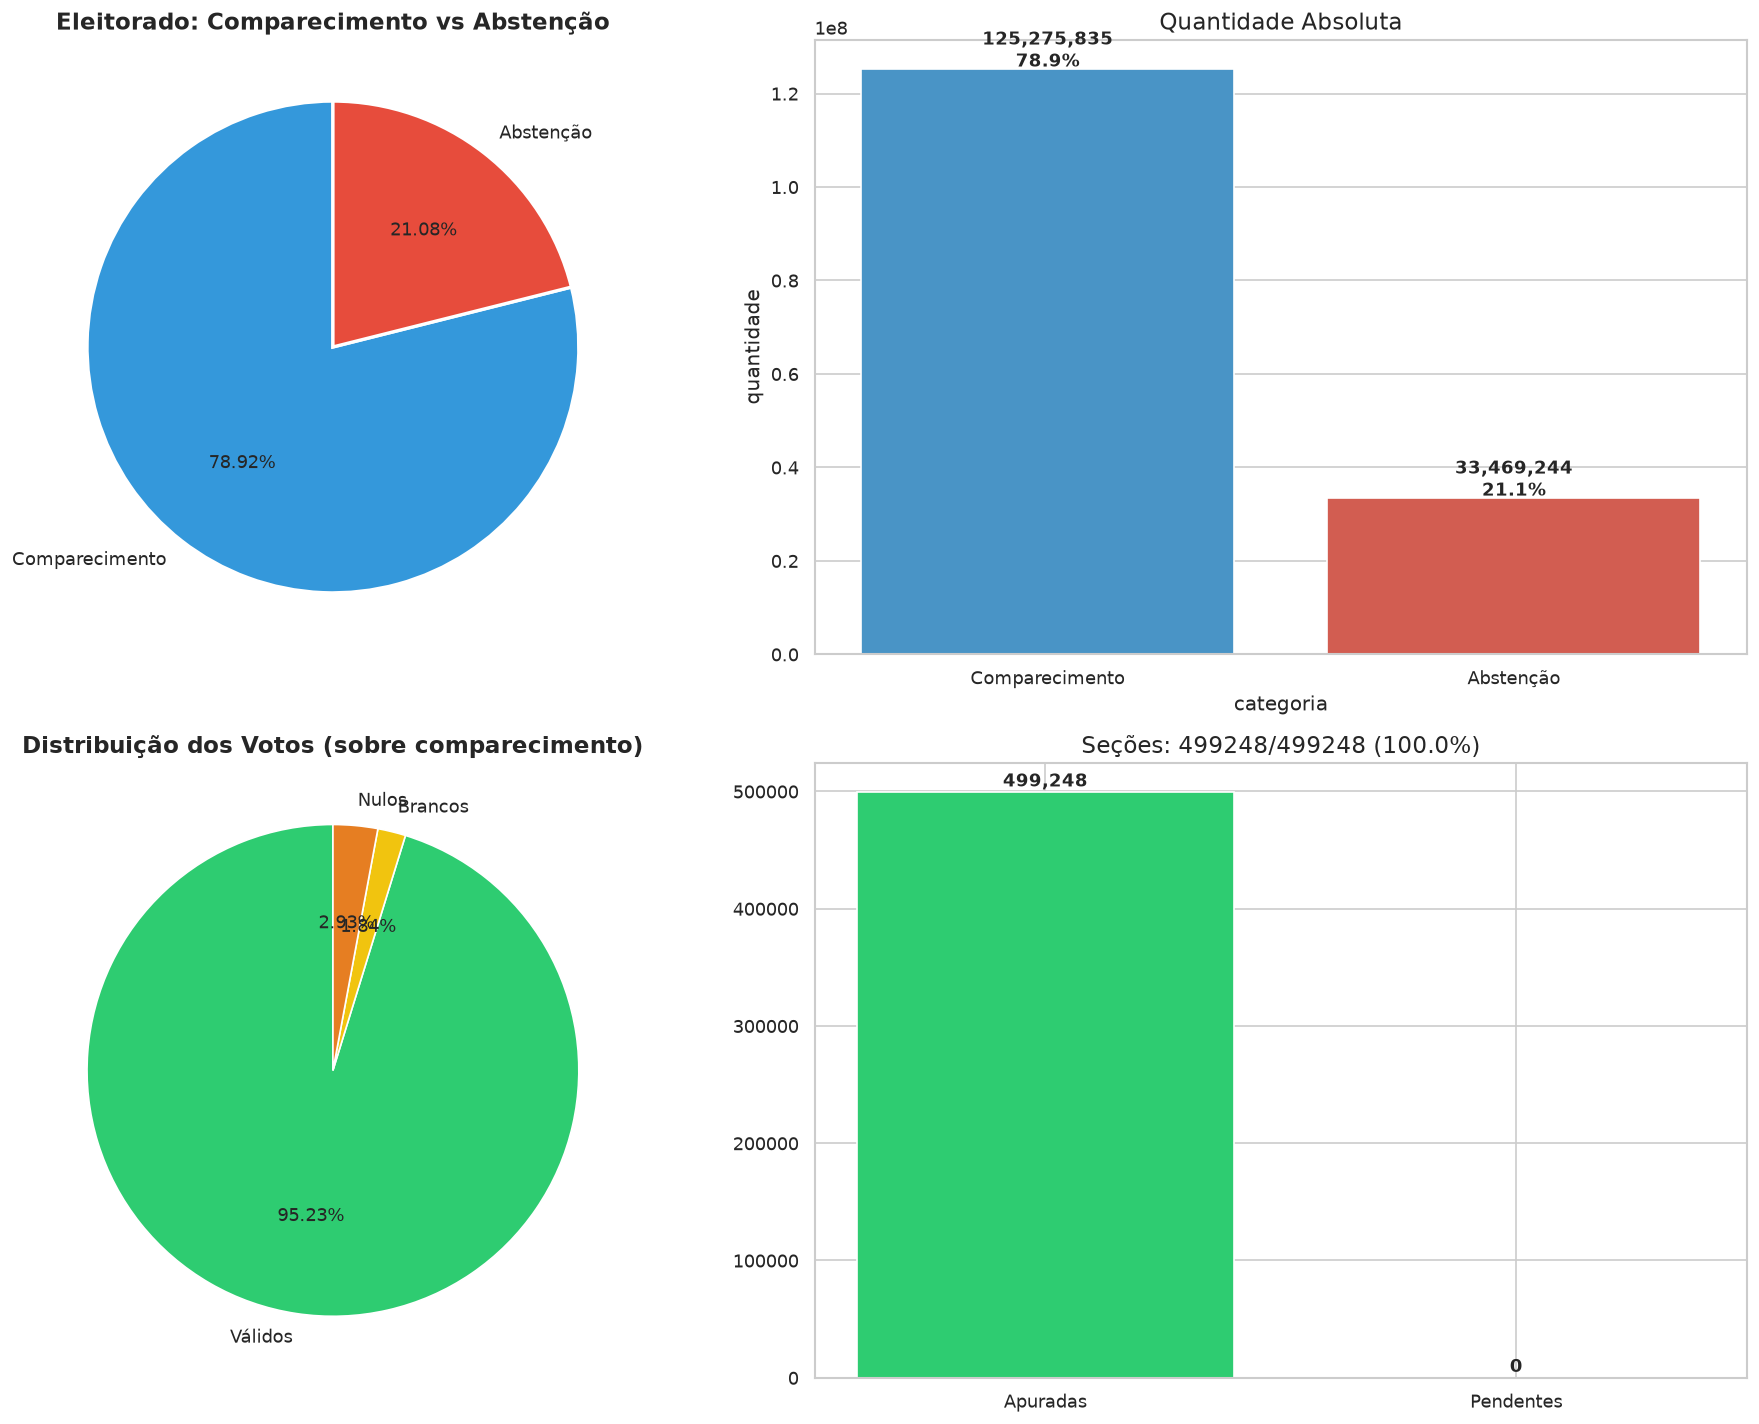

In [3]:

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Comparecimento vs Abstenção - Pizza
axes[0,0].pie([latest['comparecimento'], latest['abstencao']],
              labels=['Comparecimento', 'Abstenção'],
              autopct='%1.2f%%', colors=['#3498db', '#e74c3c'], startangle=90,
              wedgeprops={'edgecolor':'white', 'linewidth':2})
axes[0,0].set_title('Eleitorado: Comparecimento vs Abstenção', fontweight='bold')

# 2. Barras comparecimento
sns.barplot(data=df_turnout, x='categoria', y='quantidade', palette=['#3498db','#e74c3c'], ax=axes[0,1])
axes[0,1].set_title('Quantidade Absoluta')
for i, row in df_turnout.iterrows():
    axes[0,1].text(i, row['quantidade']+500000, f"{row['quantidade']:,}\n{row['pct_eleitorado']:.1f}%", ha='center', fontweight='bold')

# 3. Votos por tipo - detalhado
votos_tipos = pd.DataFrame([
    {'tipo': 'Válidos', 'qtd': latest['votos_validos'], 'pct': latest['votos_validos']/latest['comparecimento']*100},
    {'tipo': 'Brancos', 'qtd': latest['votos_brancos'], 'pct': latest['votos_brancos']/latest['comparecimento']*100},
    {'tipo': 'Nulos', 'qtd': latest['votos_nulos'], 'pct': latest['votos_nulos']/latest['comparecimento']*100},
])
axes[1,0].pie(votos_tipos['qtd'], labels=votos_tipos['tipo'], autopct='%1.2f%%',
              colors=['#2ecc71','#f1c40f','#e67e22'], startangle=90)
axes[1,0].set_title('Distribuição dos Votos (sobre comparecimento)', fontweight='bold')

# 4. Seções
axes[1,1].bar(['Apuradas','Pendentes'], [latest['secoes_apuradas'], latest['secoes_total']-latest['secoes_apuradas']],
              color=['#2ecc71','#95a5a6'])
axes[1,1].set_title(f"Seções: {latest['secoes_apuradas']}/{latest['secoes_total']} ({latest['pct_apuradas']}%)")
for i, v in enumerate([latest['secoes_apuradas'], latest['secoes_total']-latest['secoes_apuradas']]):
    axes[1,1].text(i, v+5000, f"{v:,}", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('turnout_analysis.png', dpi=150, bbox_inches='tight')
plt.show()


## 3. Evolução Temporal de Participação

                   timestamp  pct_comparecimento  pct_abstencao  pct_validos
38 2026-10-14 00:44:57+00:00           78.916148      21.083586    95.230487
39 2026-10-14 05:25:27+00:00           78.916148      21.083586    95.230487
40 2026-10-14 10:22:09+00:00           78.916148      21.083586    95.230487
41 2026-10-14 15:14:09+00:00           78.916148      21.083586    95.230487
42 2026-10-14 19:22:15+00:00           78.916148      21.083586    95.230487


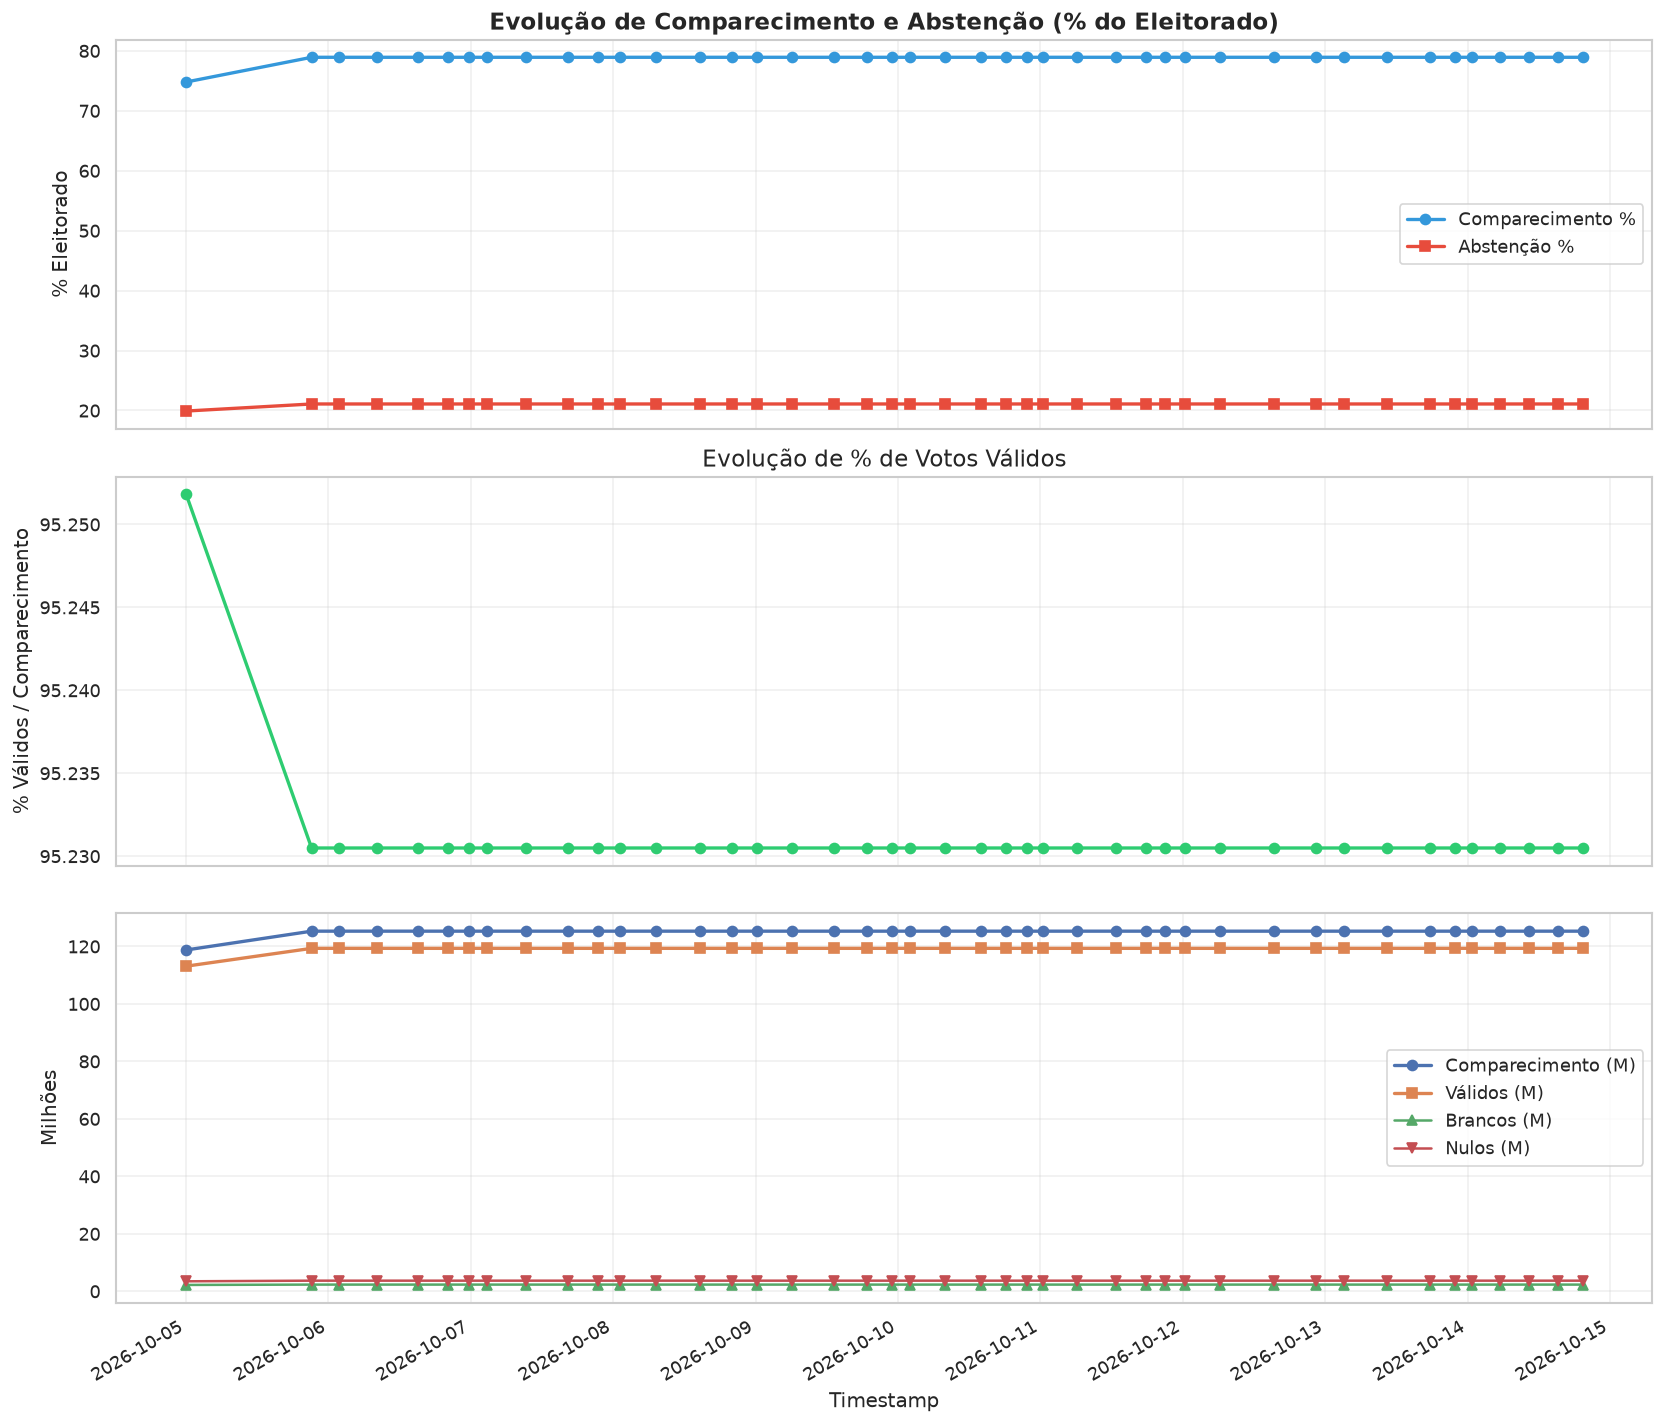

In [4]:

df_evol = pd.DataFrame([{
    'timestamp': pd.to_datetime(s['scraped_at_utc']),
    'eleitorado': s['eleitorado'],
    'comparecimento': s['comparecimento'],
    'abstencao': s['abstencao'],
    'pct_comparecimento': s['comparecimento']/s['eleitorado']*100 if s['eleitorado'] else 0,
    'pct_abstencao': s['abstencao']/s['eleitorado']*100 if s['eleitorado'] else 0,
    'votos_validos': s['votos_validos'],
    'votos_brancos': s['votos_brancos'],
    'votos_nulos': s['votos_nulos'],
    'pct_validos': s['votos_validos']/s['comparecimento']*100 if s['comparecimento'] else 0,
} for s in all_snapshots]).sort_values('timestamp')

print(df_evol[['timestamp','pct_comparecimento','pct_abstencao','pct_validos']].tail())

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# Comparecimento %
axes[0].plot(df_evol['timestamp'], df_evol['pct_comparecimento'], marker='o', color='#3498db', linewidth=2, label='Comparecimento %')
axes[0].plot(df_evol['timestamp'], df_evol['pct_abstencao'], marker='s', color='#e74c3c', linewidth=2, label='Abstenção %')
axes[0].set_ylabel('% Eleitorado')
axes[0].set_title('Evolução de Comparecimento e Abstenção (% do Eleitorado)', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Votos válidos %
axes[1].plot(df_evol['timestamp'], df_evol['pct_validos'], marker='o', color='#2ecc71', linewidth=2)
axes[1].set_ylabel('% Válidos / Comparecimento')
axes[1].set_title('Evolução de % de Votos Válidos')
axes[1].grid(True, alpha=0.3)

# Quantidades absolutas
axes[2].plot(df_evol['timestamp'], df_evol['comparecimento']/1e6, marker='o', label='Comparecimento (M)', linewidth=2)
axes[2].plot(df_evol['timestamp'], df_evol['votos_validos']/1e6, marker='s', label='Válidos (M)', linewidth=2)
axes[2].plot(df_evol['timestamp'], df_evol['votos_brancos']/1e6, marker='^', label='Brancos (M)', linewidth=1.5)
axes[2].plot(df_evol['timestamp'], df_evol['votos_nulos']/1e6, marker='v', label='Nulos (M)', linewidth=1.5)
axes[2].set_ylabel('Milhões')
axes[2].set_xlabel('Timestamp')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.savefig('turnout_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()


## 4. Análise de Votos Brancos e Nulos - Protesto?

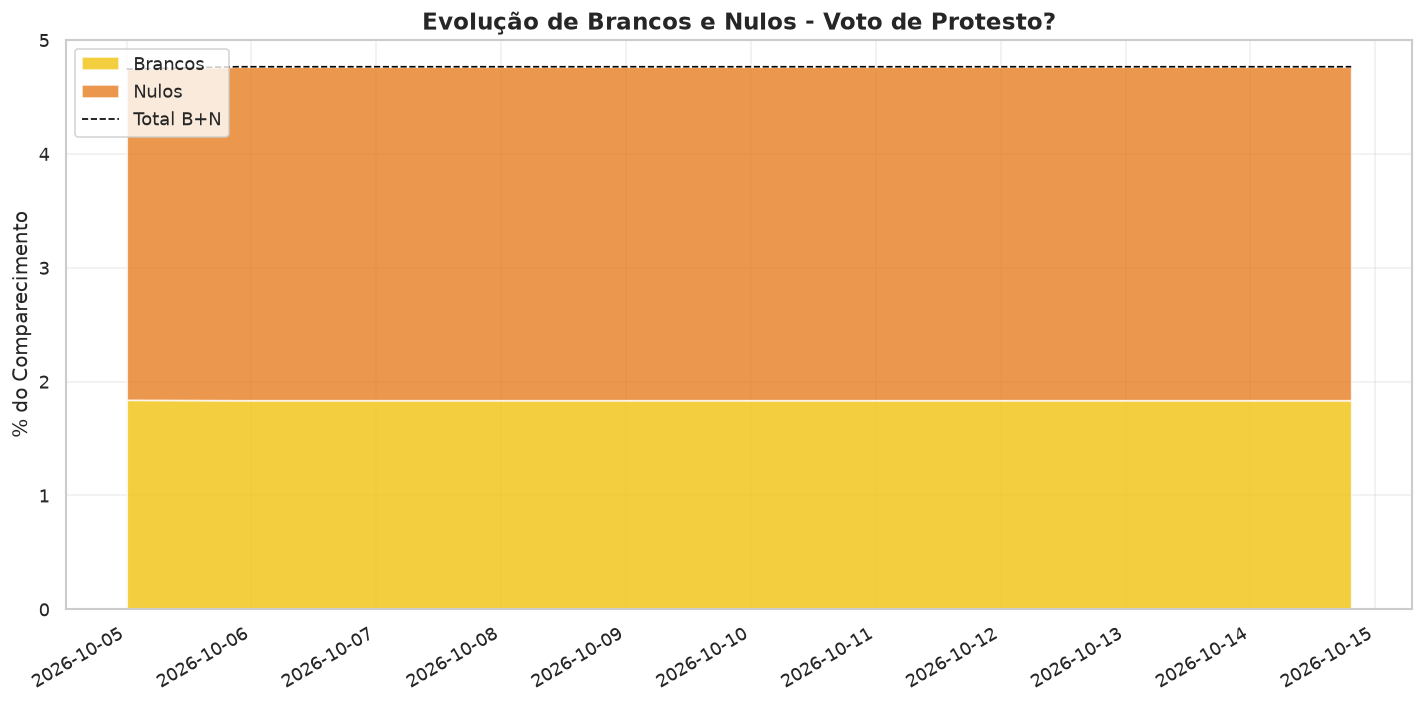

Brancos+Nulos no último snapshot: 4.77% do comparecimento
  Brancos: 1.84%
  Nulos: 2.93%


In [5]:

# Brancos + Nulos as % of electorate
df_evol['pct_brancos_nulos'] = (df_evol['votos_brancos'] + df_evol['votos_nulos']) / df_evol['comparecimento'] * 100
df_evol['pct_brancos'] = df_evol['votos_brancos'] / df_evol['comparecimento'] * 100
df_evol['pct_nulos'] = df_evol['votos_nulos'] / df_evol['comparecimento'] * 100

plt.figure(figsize=(12, 6))
plt.stackplot(df_evol['timestamp'], df_evol['pct_brancos'], df_evol['pct_nulos'],
              labels=['Brancos', 'Nulos'], colors=['#f1c40f','#e67e22'], alpha=0.8)
plt.plot(df_evol['timestamp'], df_evol['pct_brancos_nulos'], color='black', linestyle='--', linewidth=1, label='Total B+N')
plt.ylabel('% do Comparecimento')
plt.title('Evolução de Brancos e Nulos - Voto de Protesto?', fontweight='bold')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.gcf().autofmt_xdate()
plt.tight_layout()
plt.savefig('protest_votes.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Brancos+Nulos no último snapshot: {df_evol['pct_brancos_nulos'].iloc[-1]:.2f}% do comparecimento")
print(f"  Brancos: {df_evol['pct_brancos'].iloc[-1]:.2f}%")
print(f"  Nulos: {df_evol['pct_nulos'].iloc[-1]:.2f}%")


## 5. Eficiência da Apuração - Votos por Seção

                   timestamp  secoes  eleitorado_apurado  \
38 2026-10-14 00:44:57+00:00  499248         158745502.0   
39 2026-10-14 05:25:27+00:00  499248         158745502.0   
40 2026-10-14 10:22:09+00:00  499248         158745502.0   
41 2026-10-14 15:14:09+00:00  499248         158745502.0   
42 2026-10-14 19:22:15+00:00  499248         158745502.0   

    media_eleitores_secao  media_comparecimento_secao  
38              317.96923                  250.929067  
39              317.96923                  250.929067  
40              317.96923                  250.929067  
41              317.96923                  250.929067  
42              317.96923                  250.929067  


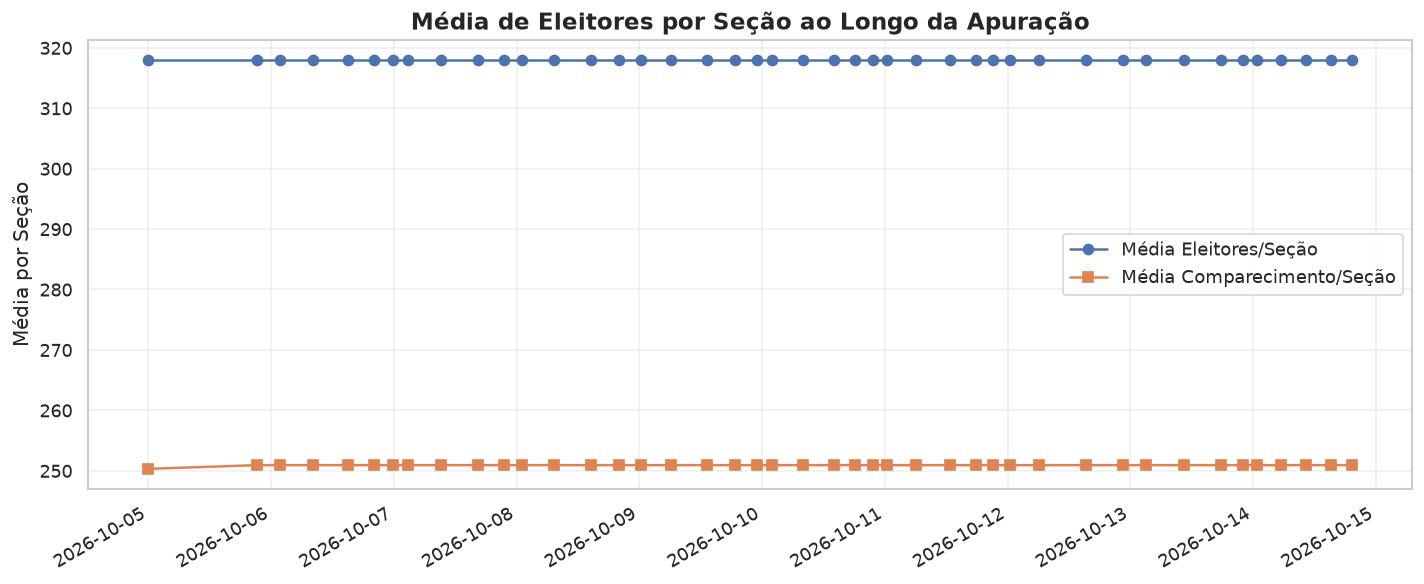

In [6]:

df_evol['votos_por_secao'] = df_evol['comparecimento'] / df_evol['eleitorado'] * 100  # actually turnout, let's compute media
# More interesting: avg voters per section
df_sections_evol = pd.DataFrame([{
    'timestamp': pd.to_datetime(s['scraped_at_utc']),
    'secoes': s['secoes_apuradas'],
    'eleitorado_apurado': s['eleitorado'] * (s['pct_apuradas']/100) if s['pct_apuradas'] else s['eleitorado'],
    'media_eleitores_secao': s['eleitorado'] / s['secoes_total'] if s['secoes_total'] else 0,
    'media_comparecimento_secao': s['comparecimento'] / s['secoes_apuradas'] if s['secoes_apuradas'] else 0
} for s in all_snapshots]).sort_values('timestamp')

print(df_sections_evol.tail())

plt.figure(figsize=(12, 5))
plt.plot(df_sections_evol['timestamp'], df_sections_evol['media_eleitores_secao'], label='Média Eleitores/Seção', marker='o')
plt.plot(df_sections_evol['timestamp'], df_sections_evol['media_comparecimento_secao'], label='Média Comparecimento/Seção', marker='s')
plt.ylabel('Média por Seção')
plt.title('Média de Eleitores por Seção ao Longo da Apuração', fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.gcf().autofmt_xdate()
plt.tight_layout()
plt.savefig('avg_per_section.png', dpi=150, bbox_inches='tight')
plt.show()
